## Визуальный анализ данных о медицинском страховании

**Цель:** Изучить данные клиентов и визуализировать ключевые факторы, влияющие на размер страхового взноса (`charges`), для подготовки аналитической записки для руководства.

**Датасет:** `insurance.csv` (возраст, пол, BMI, количество детей, статус курения, регион, стоимость полиса).

In [3]:
# Шаг 1: Импорт необходимых библиотек
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Шаг 2: Настройка глобального стиля отображения графиков для всего документа
sns.set_theme(style="whitegrid")

print("Библиотеки загружены, стиль настроен ✅")

Библиотеки загружены, стиль настроен ✅


In [4]:
# Шаг 3: Загрузка датасета
df = pd.read_csv('insurance.csv')

# Шаг 4: Просмотр названий столбцов и первых строк таблицы
print("Названия столбцов:", df.columns.tolist())
print("\nРазмер датасета (строки, столбцы):", df.shape)
print("-" * 50)
df.head()

Названия столбцов: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Размер датасета (строки, столбцы): (1338, 7)
--------------------------------------------------


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Этап 1: Общий взгляд на данные

Построим матрицу парных графиков (`pairplot`), чтобы оценить распределения и взаимосвязи между числовыми переменными. Для наглядности раскрасим данные по признаку курения (`smoker`), так как это ключевой фактор риска в страховании.


/opt/anaconda3/envs/dataviz/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


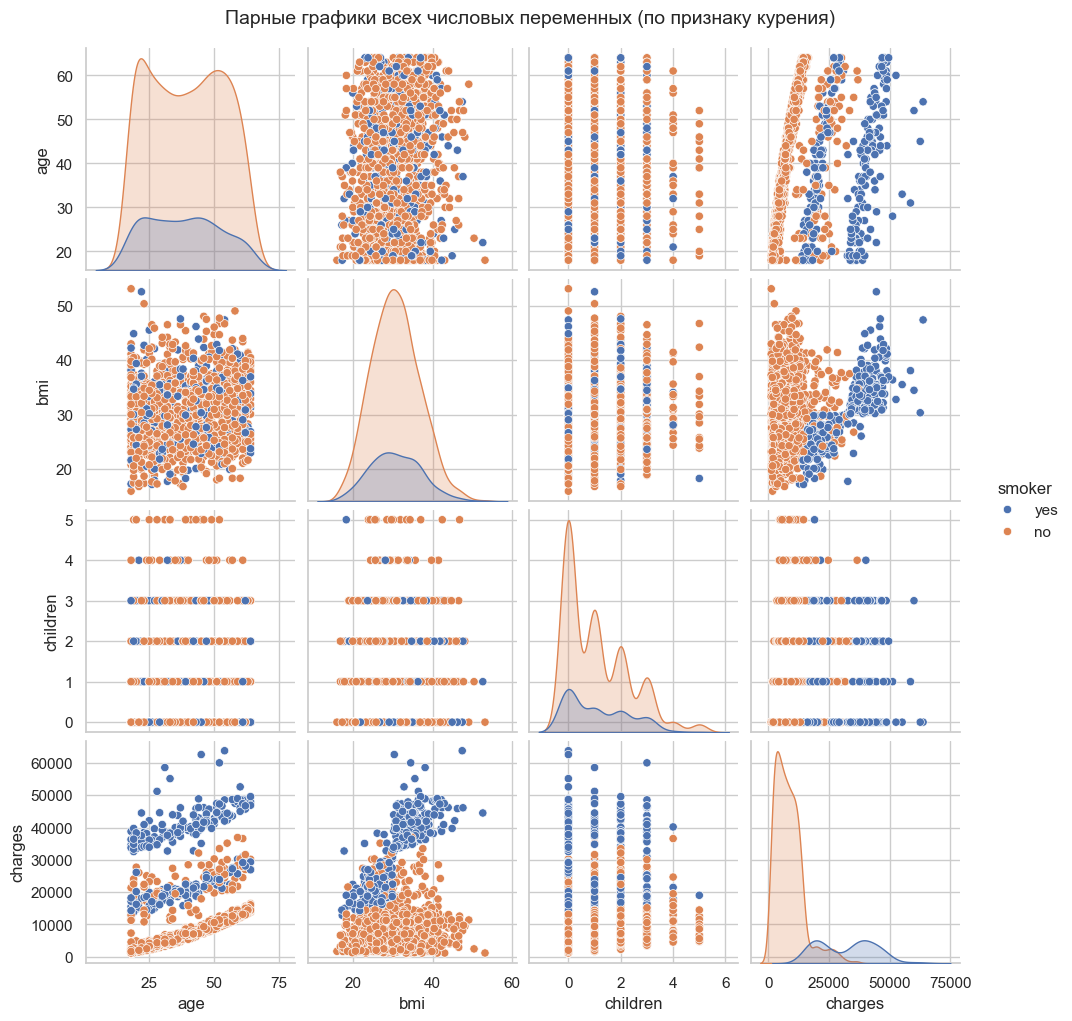

In [5]:
# Шаг 5: Визуализация всех переменных с раскраской по качественному признаку (smoker)
sns.pairplot(df, hue='smoker', height=2.5)

plt.suptitle('Парные графики всех числовых переменных (по признаку курения)', y=1.02, fontsize=14)
plt.show()

### Этап 2: Фокус на ключевых зависимостях

На предыдущем графике видно, что стоимость полиса (`charges`) сильно зависит от возраста (`age`) и индекса массы тела (`bmi`), особенно в группе курящих. 
Выделим именно эти зависимости, используя параметры `x_vars` и `y_vars`.

/opt/anaconda3/envs/dataviz/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


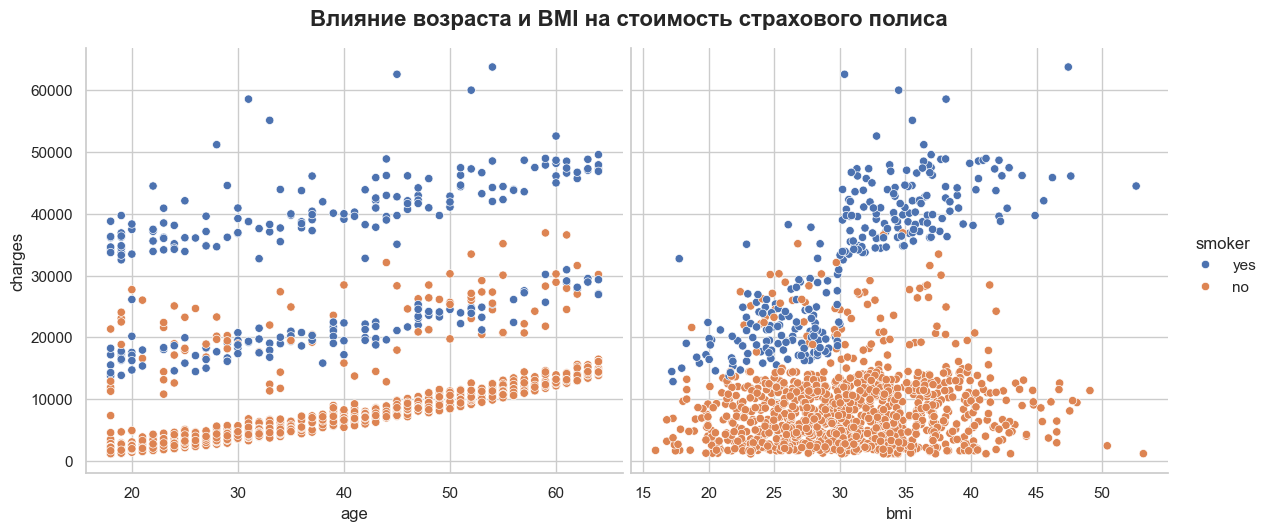

In [6]:
# Шаг 6: Вывод только информативных зависимостей для стоимости полиса
sns.pairplot(
    df, 
    x_vars=['age', 'bmi'],  # Переменные по оси X
    y_vars=['charges'],      # Переменная по оси Y
    hue='smoker',            # Раскраска по курению
    height=5,                # Размер каждого графика
    aspect=1.2               # Пропорции (ширина)
)

plt.suptitle('Влияние возраста и BMI на стоимость страхового полиса', y=1.05, fontsize=16, fontweight='bold')
plt.show()

### Этап 3: Детальная кастомизация главного графика

Для презентации руководству выберем наиболее показательный график: **зависимость стоимости полиса (`charges`) от индекса массы тела (`bmi`)**. 
Мы настроим его профессионально: добавим заголовок, подписи осей, разные формы маркеров и цвета для групп.

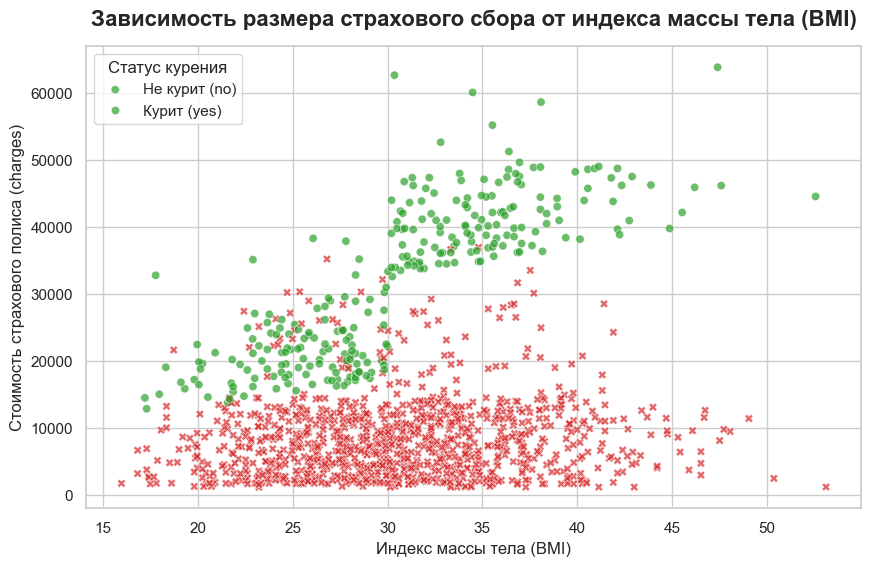

In [7]:
# Шаг 7-13: Кастомизация scatterplot для бизнес-презентации

plt.figure(figsize=(10, 6)) # Шаг 9: задаем размер холста, чтобы заголовок не наезжал

sns.scatterplot(
    data=df,
    x='bmi',
    y='charges',
    hue='smoker',               # Шаг 10: раскраска по категориальной переменной
    style='smoker',             # Шаг 11: разные формы точек для групп
    markers=['o', 'X'],         # Шаг 11: 'o' (круг) для no, 'X' (крестик) для yes
    palette=['#2ca02c', '#d62728'], # Шаг 12: настройка цветов (зеленый и красный)
    alpha=0.7                   # Дополнительная настройка: прозрачность точек
)

# Шаг 9: Настройка заголовка и осей (размер, расположение, отступы)
plt.title('Зависимость размера страхового сбора от индекса массы тела (BMI)', 
          fontsize=16, pad=15, fontweight='bold')
plt.xlabel('Индекс массы тела (BMI)', fontsize=12)
plt.ylabel('Стоимость страхового полиса (charges)', fontsize=12)

# Настройка легенды для понятности бизнесу
plt.legend(title='Статус курения', labels=['Не курит (no)', 'Курит (yes)'], fontsize=11)

# Шаг 13: Отображение графика
plt.show()

### Этап 4: Добавление линии тренда и доверительного интервала

Чтобы показать статистическую значимость выявленной тенденции, добавим линию линейной регрессии и 95% доверительный интервал с помощью функции `lmplot()`.

/opt/anaconda3/envs/dataviz/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


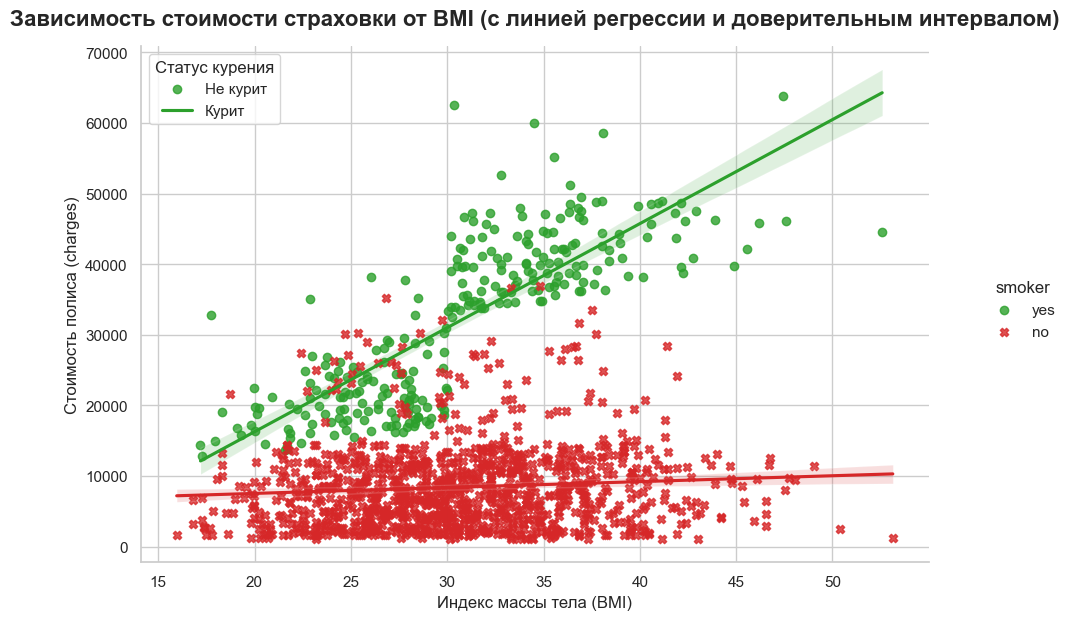

In [8]:
# Шаг 14: Построение точечной диаграммы с линией регрессии и доверительным интервалом
sns.lmplot(
    data=df,
    x='bmi',
    y='charges',
    hue='smoker',
    height=6,
    aspect=1.5,
    palette=['#2ca02c', '#d62728'],
    markers=['o', 'X'],
    ci=95  # 95% доверительный интервал (по умолчанию, но указываем явно)
)

# Шаг 15: Настройка заголовка, осей и легенды для lmplot
plt.title('Зависимость стоимости страховки от BMI (с линией регрессии и доверительным интервалом)', 
          fontsize=16, pad=15, fontweight='bold')
plt.xlabel('Индекс массы тела (BMI)', fontsize=12)
plt.ylabel('Стоимость полиса (charges)', fontsize=12)
plt.legend(title='Статус курения', labels=['Не курит', 'Курит'], fontsize=11)

plt.show()

### Этап 5: Сегментация данных (Facet Grid)

Проверим, сохраняются ли выявленные закономерности при разбивке по другой категориальной переменной, например, по полу (`sex`).

/opt/anaconda3/envs/dataviz/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


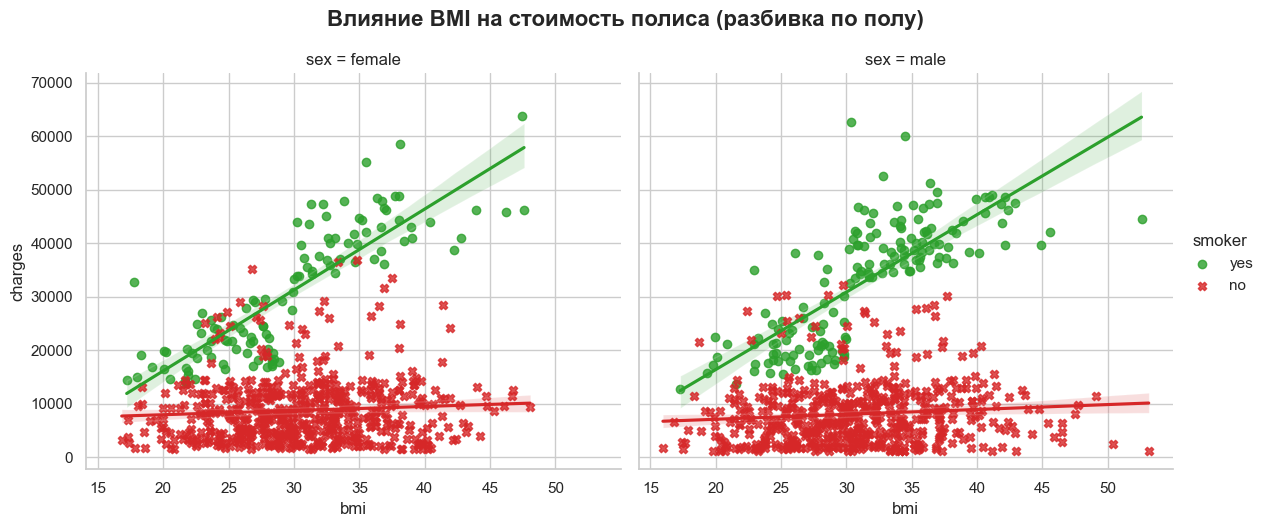

In [9]:
# Шаг 16: Разбивка графика на отдельные части по полу с помощью параметра col
sns.lmplot(
    data=df,
    x='bmi',
    y='charges',
    hue='smoker',
    col='sex',                # Разбиваем на колонки по полу
    height=5,
    aspect=1.2,
    palette=['#2ca02c', '#d62728'],
    markers=['o', 'X'],
    ci=95
)

# Общий заголовок для всей сетки графиков
plt.suptitle('Влияние BMI на стоимость полиса (разбивка по полу)', 
             fontsize=16, fontweight='bold', y=1.05)

plt.show()

### Этап 6: Экспорт результатов

Сохраняем итоговый график в формате PNG высокого качества для включения в отчет или презентацию.

ValueError: weight='has' is invalid

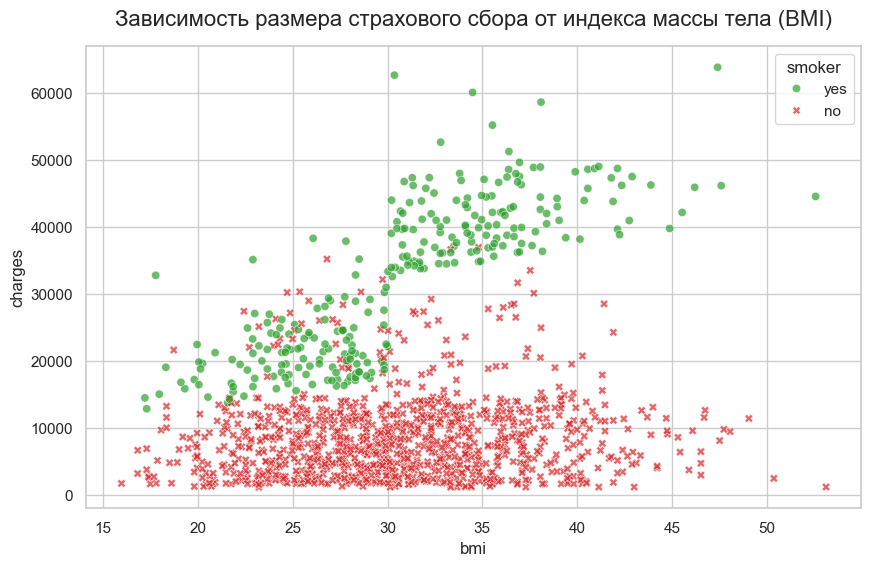

In [10]:
# Шаг 17: Экспорт графика с помощью savefig
# Создаем график заново для сохранения (или можно сохранить последний отображенный)
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df, x='bmi', y='charges', hue='smoker', 
    style='smoker', markers=['o', 'X'], palette=['#2ca02c', '#d62728'], alpha=0.7
)

plt.title('Зависимость размера страхового сбора от индекса массы тела (BMI)', fontsize=16, pad=15, fontweight='has')
plt.xlabel('Индекс массы тела (BMI)', fontsize=12)
plt.ylabel('Стоимость страхового полиса (charges)', fontsize=12)
plt.legend(title='Статус курения', labels=['Не курит (no)', 'Курит (yes)'])

# Сохраняем график в папку проекта
plt.savefig('final_bmi_charges_analysis.png', dpi=300, bbox_inches='tight')
print("График успешно сохранен как 'final_bmi_charges_analysis.png' ✅")